In [2]:
!pip install mne

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Extracting EDF parameters from /content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 183599  =      0.000 ...   367.198 secs...
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
<Info | 8 non-empty values
 bads: []
 ch_names: Trig, Fp1-LE, Fp2-LE, F3-LE, F4-LE, C3-LE, C4-LE, P3-LE, P4-LE, ...
 chs: 20 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 250.0 Hz
 meas_date: 2025-02-25 22:59:29 UTC
 nchan: 20
 projs: []
 sfreq: 500.0 Hz
 subject_info: <subject_info | his_id: Azam>
>
Using matplotlib as 2D backend.


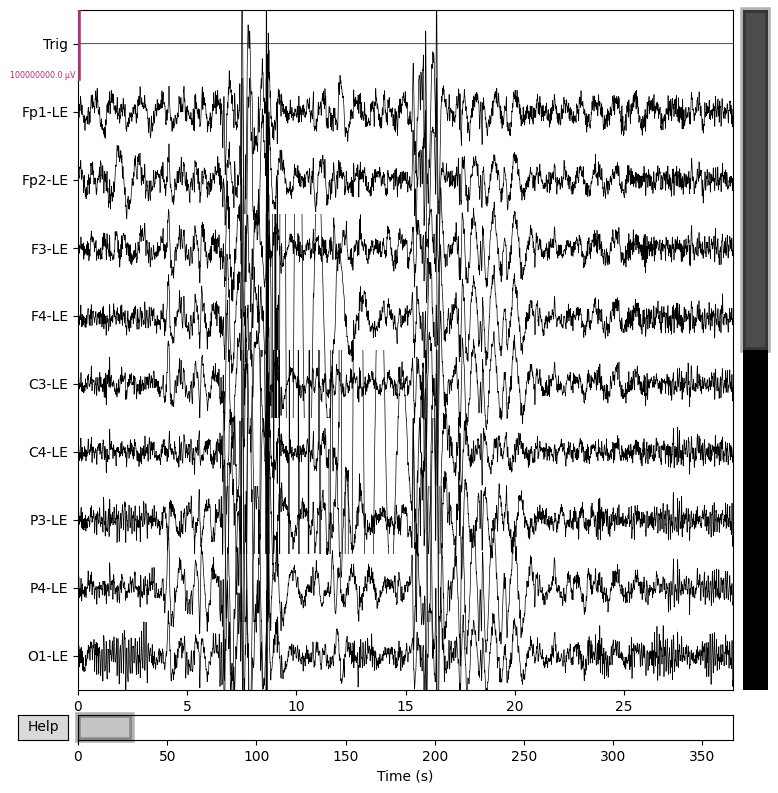

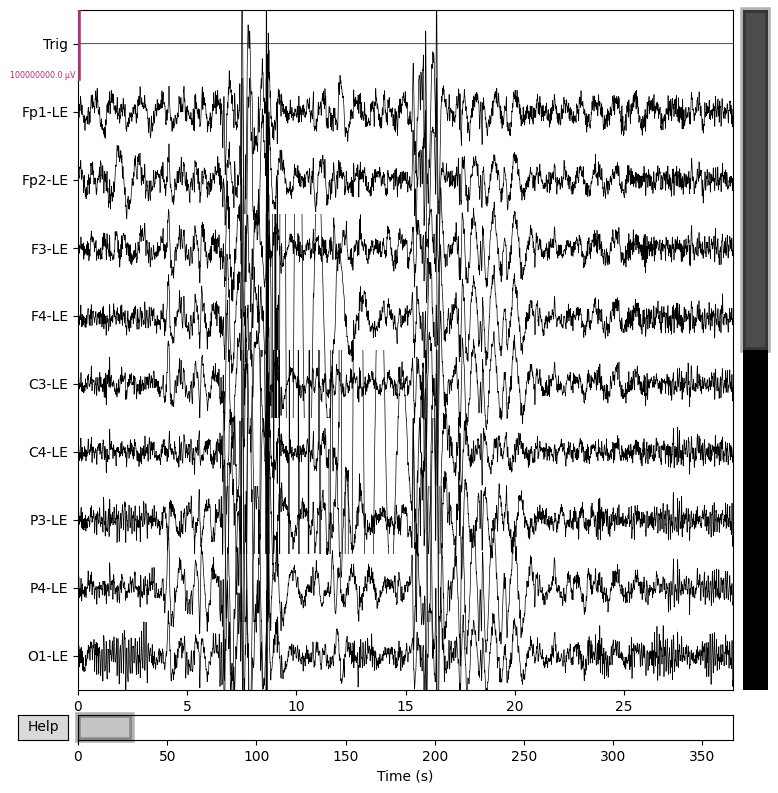

In [4]:
import mne

edf_path = '/content/drive/MyDrive/EEG_Processing_Python/SUB_01.edf'
raw = mne.io.read_raw_edf(edf_path, preload=True)
raw.pick_types(eeg=True)  # Only EEG channels

# View basic info
print(raw.info)
raw.plot(n_channels=10, duration=30, scalings=50)

In [5]:
# Remove unwanted channels (e.g., ECG, EOG, MEG)
channels_to_drop = ['Trig']  # Replace with your own list
raw.drop_channels([ch for ch in channels_to_drop if ch in raw.ch_names])

<RawEDF | SUB_01.edf, 19 x 183600 (367.2 s), ~26.6 MiB, data loaded>

Filtering raw data in 1 contiguous segment
Setting up low-pass filter at 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal lowpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 165 samples (0.330 s)

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).


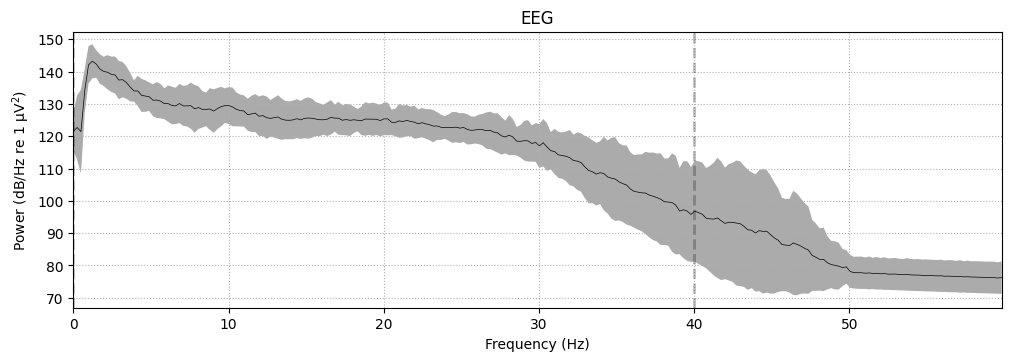

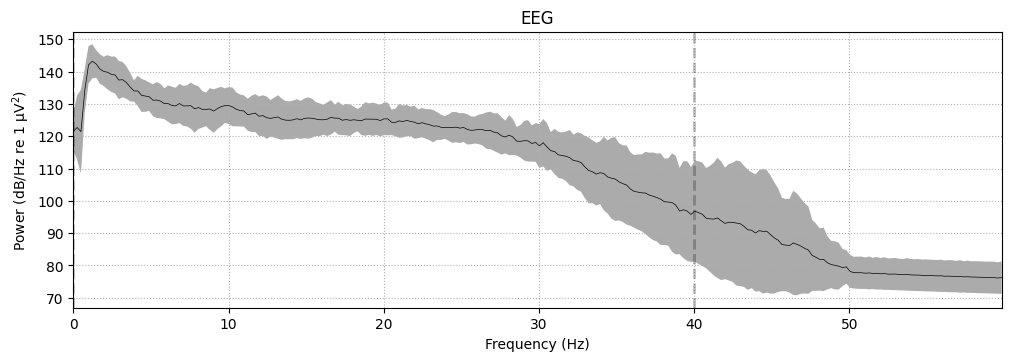

In [6]:
# Low-pass filter (e.g., below 40 Hz)
raw_low = raw.filter(None, 40, fir_design='firwin')
raw_low.plot_psd(fmax=60, average=True, show=True, spatial_colors=False)

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 1651 samples (3.302 s)

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).


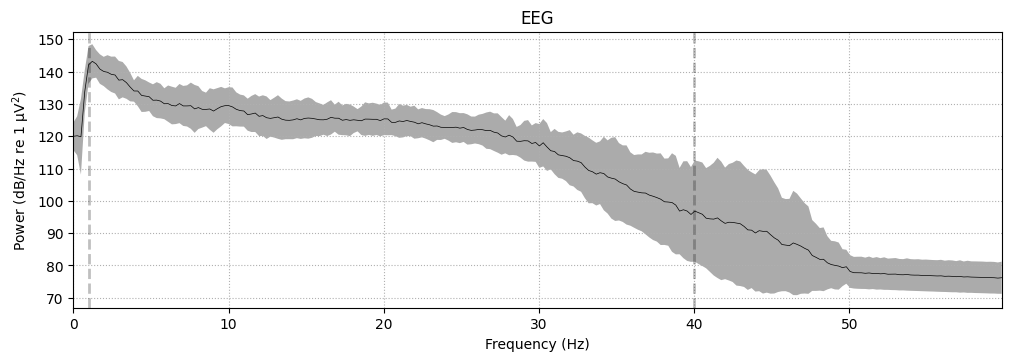

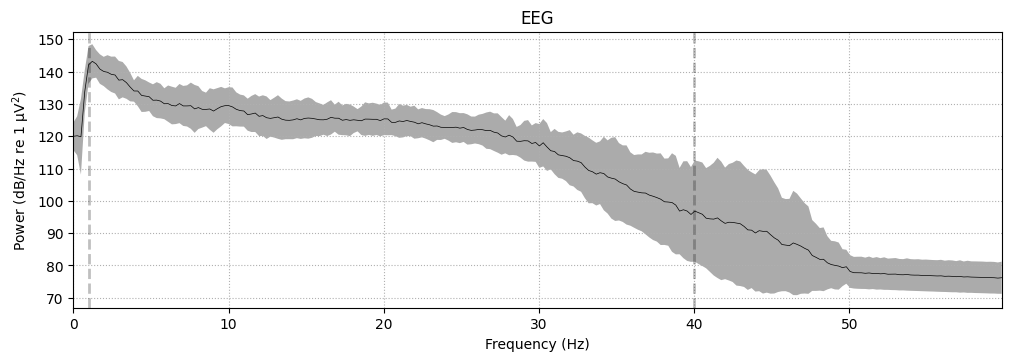

In [7]:
# High-pass filter (e.g., above 1 Hz)
raw_high = raw.filter(1, None, fir_design='firwin')
raw_high.plot_psd(fmax=60, average=True, show=True, spatial_colors=False)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 3301 samples (6.602 s)

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).


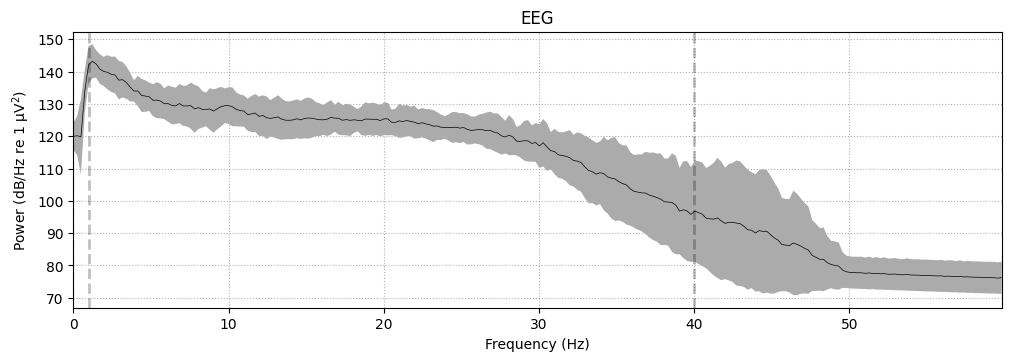

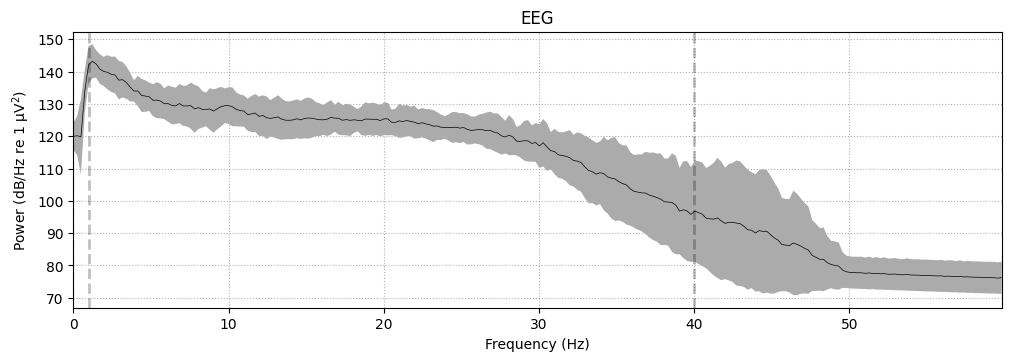

In [8]:
# Notch filter (e.g., remove 50/60 Hz line noise)
raw_notch = raw.copy().notch_filter(freqs=[50], fir_design='firwin')
raw_notch.plot_psd(fmax=60, average=True, show=True, spatial_colors=False)

In [ ]:
# Run ICA

In [9]:
# -------------------------------
# ✅ Install necessary libraries
# -------------------------------
!pip install neurokit2 antropy nolds pyentrp


In [10]:

# -------------------------------
# ✅ Import libraries
# -------------------------------
import neurokit2 as nk
import numpy as np
import matplotlib.pyplot as plt
import antropy as ant
import nolds
from pyentrp import entropy as ent


(19, 183600)
(20000,)


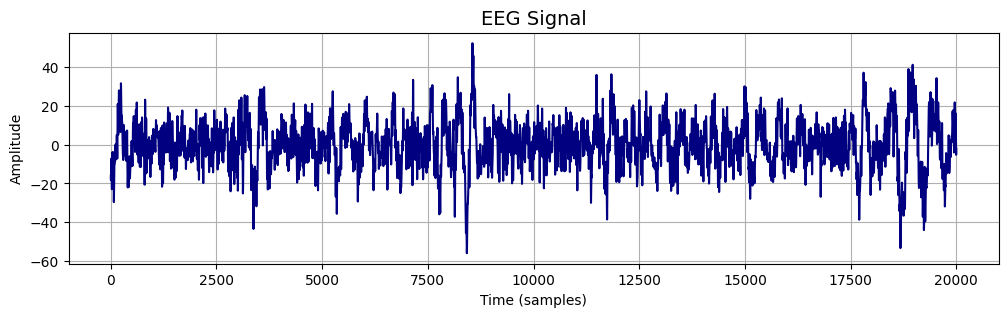

In [11]:
eeg = raw.get_data()
print(eeg.shape)
eeg_signal = eeg[1,20000:40000]
print(eeg_signal.shape)
# Plot the EEG signal
plt.figure(figsize=(12, 3))
plt.plot(eeg_signal, color='navy')
plt.title("EEG Signal", fontsize=14)
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


In [12]:

# -------------------------------
# ✅ Compute complexity measures
# -------------------------------
complexity_results = {}

# Approximate Entropy
complexity_results["Approximate Entropy"] = nk.entropy_approximate(eeg_signal)


In [13]:
# # Compute Multiscale Entropy manually
mse_result = nk.entropy_multiscale(eeg_signal)
# Access just the multiscale entropy values (an array)
mse_values = mse_result[1]['Value']
# Example: print the entropy values
print(mse_values)
# If you want a summary value (like the mean):
mse_mean = np.mean(mse_values)
print("Mean MSE:", mse_mean)
# Optionally, update your results dictionary
complexity_results["Multiscale Entropy"] = mse_mean


[ 0.3456269   0.58890652  0.83151125 ... -0.         -0.
 -0.        ]
Mean MSE: 0.2675639130374423


In [14]:

# # Sample Entropy
complexity_results["Sample Entropy"] = nk.entropy_sample(eeg_signal)


In [15]:

# # Fuzzy Entropy
complexity_results["Fuzzy Entropy"] = nk.entropy_fuzzy(eeg_signal)


In [16]:

# # Kolmogorov-Sinai Entropy (approximated via Permutation Entropy)
complexity_results["Kolmogorov–Sinai Entropy"] = ant.perm_entropy(eeg_signal)


In [17]:

# Correlation Dimension
complexity_results["Correlation Dimension"] = nolds.corr_dim(eeg_signal, emb_dim=10)

# Detrended Fluctuation Analysis (DFA)
complexity_results["DFA"] = nolds.dfa(eeg_signal)

# Katz Fractal Dimension
complexity_results["Katz FD"] = ant.katz_fd(eeg_signal)

# Higuchi Fractal Dimension
complexity_results["Higuchi FD"] = ant.higuchi_fd(eeg_signal)

# Hurst Exponent
complexity_results["Hurst Exponent"] = nolds.hurst_rs(eeg_signal)

# Lyapunov Exponent
complexity_results["Lyapunov Exponent"] = nolds.lyap_r(eeg_signal)

# Lempel-Ziv Complexity
complexity_results["Lempel–Ziv Complexity"] = ant.lziv_complexity(eeg_signal)


In [19]:

# -------------------------------
# ✅ Print results as a table
# -------------------------------
# Fix the dictionary to ensure all values are floats
for key in complexity_results:
    if isinstance(complexity_results[key], tuple):
        complexity_results[key] = complexity_results[key][0]  # keep only the float value

# Now print nicely
print("\nComplexity Metrics:")
for key, value in complexity_results.items():
    print(f"{key:30}: {value:.4f}")




Complexity Metrics:
Approximate Entropy           : 0.4904
Multiscale Entropy            : 0.2676
Sample Entropy                : 0.4319
Fuzzy Entropy                 : 0.2770
Kolmogorov–Sinai Entropy      : 1.5036
Correlation Dimension         : 2.9045
DFA                           : 1.1038
Katz FD                       : 2.4108
Higuchi FD                    : 1.1174
Hurst Exponent                : 0.8714
Lyapunov Exponent             : 0.0087
Lempel–Ziv Complexity         : 3380.0000
